# Dagar och helgdagar

Här undersöker vi bara hur typ av dag påverkar cykeluthyrningen: veckodag, helg och helgdag.
Vi utesluter andra faktorer så som väder.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/SeoulBikeData.csv", encoding="cp1252")

df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df = df[df["Functioning Day"] == "Yes"].copy()

TARGET = "Rented Bike Count"
df.shape

(8465, 14)

## Skapa kalenderish
Datan har just nu bara datum och en helgdagskolumn. Vi delar därför upp den manuellt istället.

In [7]:
df["Veckodag"] = df["Date"].dt.day_of_week
df["Helg"] = df["Veckodag"] >= 5
df["Helgdag"] = df["Holiday"] == "Holiday"

df["Ledig dag"] = df["Helg"] | df["Helgdag"]

df[["Date", "Veckodag", "Helg", "Helgdag", "Ledig dag"]].head()

,Date,Veckodag,Helg,Helgdag,Ledig dag
0,2017-12-01,4,False,False,False
1,2017-12-01,4,False,False,False
2,2017-12-01,4,False,False,False
3,2017-12-01,4,False,False,False
4,2017-12-01,4,False,False,False


In [8]:
helgdagar = df[df["Helgdag"]]["Date"].dt.date.unique()
print("Antal helgdagar:", len(helgdagar))
print(helgdagar)

Antal helgdagar: 17
[datetime.date(2017, 12, 22) datetime.date(2017, 12, 24)
 datetime.date(2017, 12, 25) datetime.date(2017, 12, 31)
 datetime.date(2018, 1, 1) datetime.date(2018, 2, 15)
 datetime.date(2018, 2, 16) datetime.date(2018, 2, 17)
 datetime.date(2018, 3, 1) datetime.date(2018, 5, 1)
 datetime.date(2018, 5, 22) datetime.date(2018, 6, 6)
 datetime.date(2018, 8, 15) datetime.date(2018, 9, 23)
 datetime.date(2018, 9, 24) datetime.date(2018, 9, 25)
 datetime.date(2018, 10, 3)]


### 17 dagar av året består av röda dagar

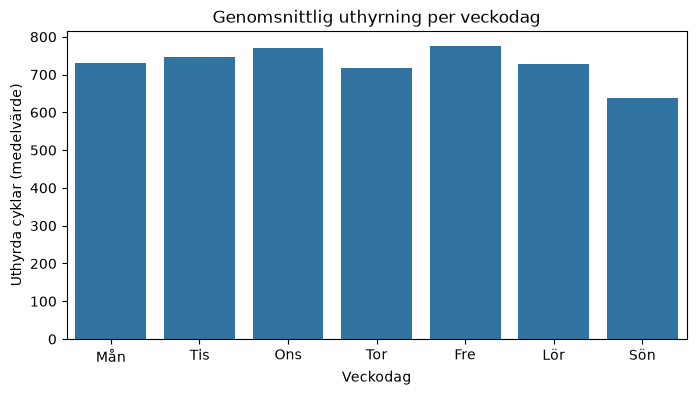

Veckodag
0    731.0
1    745.0
2    770.0
3    718.0
4    776.0
5    728.0
6    637.0
Name: Rented Bike Count, dtype: float64

In [12]:
dagnamn = ["Mån", "Tis", "Ons", "Tor", "Fre", "Lör", "Sön"]
per_dag = df.groupby("Veckodag")[TARGET].mean()

plt.figure(figsize=(8, 4))
sns.barplot(x=dagnamn, y=per_dag.values)
plt.title("Genomsnittlig uthyrning per veckodag")
plt.xlabel("Veckodag")
plt.ylabel("Uthyrda cyklar (medelvärde)")
plt.show()

per_dag.round()

**Vad syns i grafen:** Nästan alla veckodagar har en liknande mängd uthyrda cyklar. Söndag skiljer sig åt lite men det är inget större "drop".
Vi väljer därför att gå vidare för att att kolla timme för timme per veckodag.

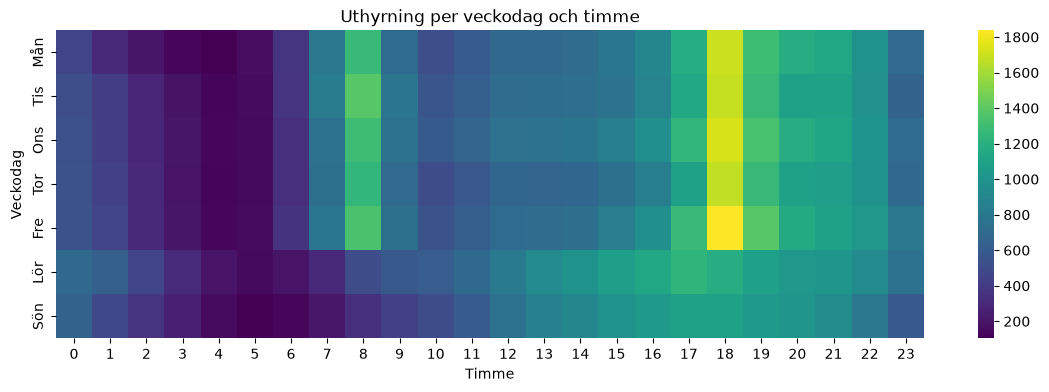

In [13]:
tabell = df.pivot_table(index="Veckodag", columns="Hour", values=TARGET, aggfunc="mean")
tabell.index = dagnamn

plt.figure(figsize=(14, 4))
sns.heatmap(tabell, cmap="viridis")
plt.title("Uthyrning per veckodag och timme")
plt.xlabel("Timme")
plt.ylabel("Veckodag")
plt.show()

**Här ser vi** att uthyrningen följer de klassiska rusningstiderna när folk tar sig till och från jobbet. Helgen är mer utspridd under dagen men lugnare på morgonen.

In [14]:
df.groupby(["Helg", "Helgdag"])[TARGET].agg(["mean", "count"]).round()

mean  count
Helg  Helgdag              
False False    756.0   5712
      True     600.0    312
True  False    698.0   2345
      True     298.0     96

**Lägst antal uthyrningar** hittar vi på helgdagar som infaller på en helg.

Dagtyp
Vanlig vardag        5712
Helg                 2345
Helgdag på vardag     312
Helgdag på helg        96
Name: count, dtype: int64


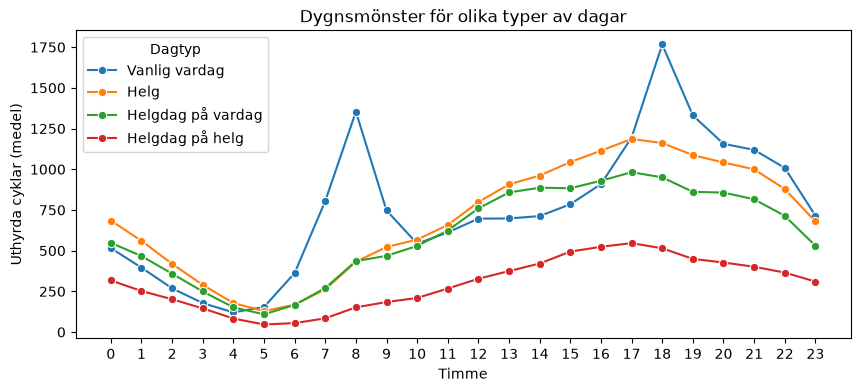

In [17]:
def dagtyp(rad):
	if rad["Helgdag"] and rad["Helg"]:
		return "Helgdag på helg"
	if rad["Helgdag"]:
		return "Helgdag på vardag"
	if rad["Helg"]:
		return "Helg"
	return "Vanlig vardag"

df["Dagtyp"] = df.apply(dagtyp, axis=1)

# Hur många rader per typ? Visar hur säker varje linje är
print(df["Dagtyp"].value_counts())

plt.figure(figsize=(10, 4))
sns.lineplot(data=df, x="Hour", y=TARGET, hue="Dagtyp", errorbar=None, marker="o")
plt.title("Dygnsmönster för olika typer av dagar")
plt.xlabel("Timme")
plt.ylabel("Uthyrda cyklar (medel)")
plt.xticks(range(0, 24))
plt.show()

**Vi ser att** helgdagar som infaller på en vardag beter sig likt en vanlig helg. Vi kan slå samman dessa värden under "ledig dag".

In [18]:
from sklearn.metrics import mean_absolute_error

# Gissning 1: bara timme
gissning_timme = df.groupby("Hour")[TARGET].transform("mean")

# Gissning 2: timme + ledig dag
gissning_ledig = df.groupby(["Hour", "Ledig dag"])[TARGET].transform("mean")

print("MAE, bara timme:        ", round(mean_absolute_error(df[TARGET], gissning_timme)))
print("MAE, timme + ledig dag: ", round(mean_absolute_error(df[TARGET], gissning_ledig)))

MAE, bara timme:         414
MAE, timme + ledig dag:  398


## Maskininlärning
Vi kommer köra en 20/80 split där 20% av datan blir testdata som inte kommer användas för upplärning

In [19]:
from sklearn.model_selection import train_test_split

X = df[["Hour", "Ledig dag"]]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Träning:", len(X_train), "rader")
print("Test:   ", len(X_test), "rader")

Träning: 6772 rader
Test:    1693 rader


## Baslinjer
Mänskliga gissningar att jämföra med. De räknas fram på **träningsdatan** (80%) och testas på
**testdatan** (20%), precis som modellerna, så att jämförelsen blir rättvis.

In [23]:
from sklearn.metrics import mean_absolute_error

gissning_medel = [y_train.mean()] * len(y_test)

tabell = pd.concat([X_train, y_train], axis=1).groupby(["Hour", "Ledig dag"])[TARGET].mean()
gissning_tabell = [tabell[(h, l)] for h, l in zip(X_test["Hour"], X_test["Ledig dag"])]

print("MAE, alltid medelvärdet:", round(mean_absolute_error(y_test, gissning_medel)))
print("MAE, tabell:            ", round(mean_absolute_error(y_test, gissning_tabell)))

MAE, alltid medelvärdet: 510
MAE, tabell:             398


**MAE, alltid medelvärdet:** gissningen är i snitt fel med 510 cyklar per timme. Det beror på att
den alltid gissar samma tal (~731), medelvärdet av alla timmar på alla dagar i träningsdatan.
Den tar ingen hänsyn till om det är natt eller rusningstid.

**MAE, tabell:** när gissningen istället slår upp medelvärdet för just den timmen och om det är
en ledig dag, sjunker felet till 398 cyklar per timme.

**Det här är de två siffrorna modellerna måste slå.**

In [24]:
from sklearn.linear_model import LinearRegression

modell_lr = LinearRegression()
modell_lr.fit(X_train, y_train)
pred_lr = modell_lr.predict(X_test)
print("MAE, linjär regression:", round(mean_absolute_error(y_test, pred_lr)))

MAE, linjär regression: 444


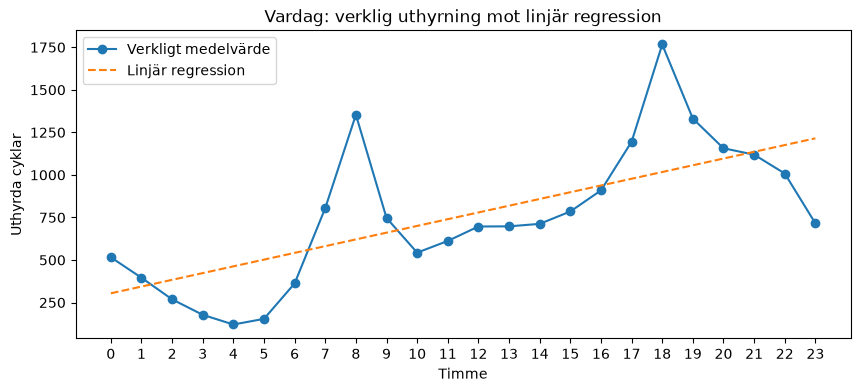

In [29]:
# Modellen gissa alla 24 timmar på en vanlig vardag
timmar = pd.DataFrame({"Hour": range(24), "Ledig dag": False})
linje = modell_lr.predict(timmar)

# Medelvärdet per timme på vardagar
verkligt = df[~df["Ledig dag"]].groupby("Hour")[TARGET].mean()

plt.figure(figsize=(10, 4))
plt.plot(verkligt.index, verkligt.values, marker="o", label="Verkligt medelvärde")
plt.plot(range(24), linje, linestyle="--", label="Linjär regression")
plt.title("Vardag: verklig uthyrning mot linjär regression")
plt.xlabel("Timme")
plt.ylabel("Uthyrda cyklar")
plt.xticks(range(0, 24))
plt.legend()
plt.show()

**Vad vi ser:** modellen är sämre än tabellen (444 mot 398). Linjär regression kan bara dra
en rak linje. Den missar morgontoppen kl 8 och tror att kl 23 är dygnets mest populära timme.
Vi behöver låta varje timme få ett eget värde istället för en rak linje.

## Optimering 1: timme som kategori
Istället för att se timme som ett tal gör vi om den till 24 ja/nej-kolumner.
Då lär sig modellen ett eget värde för varje timme.

In [28]:
X_onehot = pd.get_dummies(X, columns=["Hour"])

X_train_oh, X_test_oh, _, _ = train_test_split(X_onehot, y, test_size=0.2, random_state=42)

modell_oh = LinearRegression()
modell_oh.fit(X_train_oh, y_train)
pred_oh = modell_oh.predict(X_test_oh)

print("MAE, linjär regression med one-hot:", round(mean_absolute_error(y_test, pred_oh)))

#X_onehot.head()

MAE, linjär regression med one-hot: 409


**Resultatet** har sjunkit från 444 (felaktiga)cyklar till 409 vilket är bra. Dock vill vi få till ett bättre resultat som kan slå tabellen som fick resultatet 398.

Modellen tar hänsyn till ledig dag, men bara som ett fast tal som dras av
lika mycket varje timme.

## Optimering 2: timme och ledig dag som kombinerade kategorier
Ledig dag påverkar olika timmar olika mycket. Därför slår vi ihop timme och ledig dag
till 48 kategorier så att varje kombination får ett eget värde.


(.astype(str) gör om timme och ledig dag till text, så att de kan klistras ihop. + "_" + sätter ihop dem: 8 och False blir "8_False".)

In [30]:
X_komb = (X["Hour"].astype(str) + "_" + X["Ledig dag"].astype(str)).to_frame("Timme_ledig")
X_komb = pd.get_dummies(X_komb)

X_train_k, X_test_k, _, _ = train_test_split(X_komb, y, test_size=0.2, random_state=42)

modell_komb = LinearRegression()
modell_komb.fit(X_train_k, y_train)
pred_komb = modell_komb.predict(X_test_k)

print("MAE, linjär med kombinerade kategorier:", round(mean_absolute_error(y_test, pred_komb)))

MAE, linjär med kombinerade kategorier: 398


**Resultat:** felet sjönk från 409 till 398 cyklar per timme, lika bra som tabellen.
När varje kombination får ett eget värde räknar modellen i praktiken fram
samma medelvärden som tabellen. Med bara timme och ledig dag finns inget mer att lära sig.

## Optimering 3: Random Forest
Istället för att vi själva bygger kombinationerna testar vi en modell som hittar dem på egen hand.
Random Forest bygger många beslutsträd ("är timmen före kl 7? är det en ledig dag?")
och tar medelvärdet av deras gissningar.

In [34]:
from sklearn.ensemble import RandomForestRegressor

modell_rf = RandomForestRegressor(n_estimators=100, random_state=42)
modell_rf.fit(X_train, y_train)
pred_rf = modell_rf.predict(X_test)

print("MAE, Random Forest:", round(mean_absolute_error(y_test, pred_rf)))

MAE, Random Forest: 398


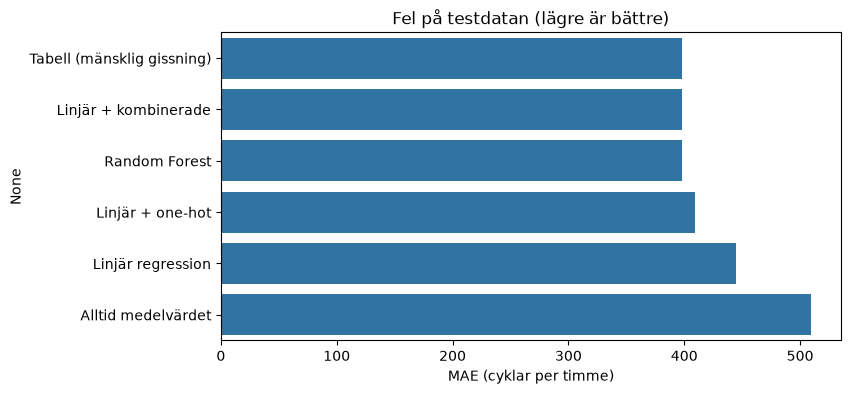

Tabell (mänsklig gissning)    398.0
Linjär + kombinerade          398.0
Random Forest                 398.0
Linjär + one-hot              409.0
Linjär regression             444.0
Alltid medelvärdet            510.0
dtype: float64

In [33]:
resultat = pd.Series({
	"Alltid medelvärdet": mean_absolute_error(y_test, gissning_medel),
	"Linjär regression": mean_absolute_error(y_test, pred_lr),
	"Linjär + one-hot": mean_absolute_error(y_test, pred_oh),
	"Linjär + kombinerade": mean_absolute_error(y_test, pred_komb),
	"Random Forest": mean_absolute_error(y_test, pred_rf),
	"Tabell (mänsklig gissning)": mean_absolute_error(y_test, gissning_tabell),
}).sort_values()

plt.figure(figsize=(8, 4))
sns.barplot(x=resultat.values, y=resultat.index)
plt.title("Fel på testdatan (lägre är bättre)")
plt.xlabel("MAE (cyklar per timme)")
plt.show()

resultat.round()

## Slutsatser

| Modell | MAE | Varför |
|---|---|---|
| Alltid medelvärdet | 510 | Vet ingenting |
| Linjär regression | 444 | Rak linje missar topparna kl 8 och 18 |
| Linjär + one-hot | 409 | Varje timme får eget värde, men ledig dag är ett enda fast tal (inte timme för timme) |
| Linjär + kombinerade | 398 | Varje timme/ledig dag-kombination får eget värde |
| Random Forest | 398 | Hittar kombinationerna själv |
| Tabell (mänsklig gissning) | 398 | Medelvärde per timme och ledig dag |

- **Optimeringarna fungerade:** felet sjönk från 444 till 398.
- **ML slår inte den mänskliga gissningen.** Med bara två features (timme | ledig dag) finns 48 kombinationer,
  och tabellen har redan det bästa svaret för varje..
- **Slutsats:** kalendern ensam räcker inte. Det återstående felet på ~400 cyklar per timme
  kan bero på andra faktorer så som vädret. Röda dagar hamnar också ofta på kallare månader vilket kan göra skillnad också.